# Alternative-Data Credit Scoring for Thin-File Applicants

### **DSA 8401 Applied Machine Learning, capstone project.** 

### **Anne Waithera Kiragu (074432), MSc Data Science and Analytics, Strathmore University**



**Background;** Many adults, in Kenya and Africa in general, have never borrowed formally, so listed credit bureaus hold no record of them ("thin-file" applicants). Lenders that rely on the bureaus either reject them or lend to them blindly. On the other hand, lenders who are focused on financial inclusion, use alternative data such as telco and transactional information, to judge whether these people can repay. In Kenya, the richest alternative data is mobile-money activity.

**The question this notebook answers;** Can alternative data, here Home Credit's own **transaction records of how people repaid past loans** (their *behaviour*), rank thin-file applicants' risk as well as a credit-bureau record does, in a way that can be explained and is fair? The aim, is that clients capable of repayment are not rejected, and that loans are sized so clients can succeed.


**The decision;** *Should a lender approve thin-file applicants, and if so, which ones, and on what loan terms?*

**Who would use this;** Any lender that wants to serve thin-file applicants, in particular Kenyan lenders that rely on the bureau and today decline everyone without a record.


| | Measure |
|---|---|
| **Primary KPI** | Default rate among approved loans (% of approved loans with payment difficulties) |
| Supporting measures | Approval rate · thin-file applicants approved · expected cost per 1,000 applicants · ranking quality (AUC) |
| Baseline: bureau-only rule | Decline everyone without a bureau record (common practice for bureau-based lenders) |

<br>

> **Data.** The public [Home Credit Default Risk](https://www.kaggle.com/c/home-credit-default-risk) data (2018): about 307,000 real, anonymised applications for cash loans and revolving credit to Home Credit, a consumer lender that serves people with little credit history. Home Credit uses telco and transactional data in its own scoring, but the public release contains only part of it: **transaction records of past loans** (every instalment due and paid, monthly card and point-of-sale balances) and a few **phone signals** on the application form. Mobile-money logs would be a further source of the same kind (transaction histories); no public dataset links them to loan outcomes, so this project tests the idea on the transaction data that does exist.

In [1]:
import pandas as pd
import numpy  as np

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore', category=PendingDeprecationWarning)    

In [2]:
# Data Loading

DATA = '../data/raw/'      
OUT  = '../reports/'       

file_path = DATA + 'application_train.csv'

df_raw = pd.read_csv(file_path)       
rows , cols = df_raw.shape

print(f'Columns {cols}\nRows:{rows}')

Columns 122
Rows:307511


### End to End Machine Learning Cycle

1. Problem statement
2. Data collection
3. Data preparation for analysis: **data quality report**
     - Duplicates · Missing values · Inconsistent data · Value types · Outliers · Coverage
4. Exploratory Data Analysis:
      1. Univariate
      2. Bivariate
      3. Multi-variate
5. Feature engineering: **repayment behaviour**
6. Data preparation for Machine Learning
   - Data Leakage · Class Imbalance · Data Transformation
7. Model training and comparison with the bureau-only rule
8. From scores to decisions: business cost and sensitivity
9. Model explanation and fairness check
10. Decision aid and saved model
11. Limitations

## 1. Problem statement

A lender must decide how to treat applicants with no bureau record, and one that relies on the bureau records, declines them.Consequently, it loses good customers and cannot grow in exactly the market that financial inclusion is about. On the other hand, approving them blindly risks more defaults.

*This notebook is the readable walkthrough of the project. The same analysis runs as a scripted pipeline (`make all`, code in `src/thinfile/`), which also serves the model through an API. The pipeline's feature code is fuller, so its numbers differ from this notebook's in the second or third decimal, however, the conclusions are the same.*

## 2. Data Collection

| File | Contents | Role |
|---|---|---|
| `application_train.csv` | one row per loan application: the applicant's form and the outcome (`TARGET`) | main table |
| `installments_payments.csv` | every instalment due and paid on the applicant's past loans with Home Credit | behaviour |
| `POS_CASH_balance.csv` | monthly status of past point-of-sale and cash loans | behaviour |
| `credit_card_balance.csv` | monthly credit-card balance, limit and payments | behaviour |
| `previous_application.csv` | earlier applications to Home Credit, approved or refused | behaviour |
| `bureau.csv` | the applicant's loans at **other** lenders, from the credit bureau | bureau |
| `bureau_balance.csv` | month-by-month status (on time / days past due) of each bureau loan | bureau |



**Unit of analysis:** one loan application (one applicant). 

**Records:** 307,511 applications, of which 8.1% defaulted. 

**Time period:** the data carries no calendar dates; histories are given in days or months *before* each application, reaching back up to about 8 years. 

## 3. Data Preparation for Analysis / Data quality report

### Data dictionary

In [3]:
# data dictionary: one row per column of df_raw
dictionary = pd.DataFrame({
    'type'      : df_raw.dtypes.astype(str),
    'missing_%' : (df_raw.isnull().mean() * 100).round(1),
    'unique'    : df_raw.nunique(),
    # first non-missing value, so the example isn't NaN
    'example'   : df_raw.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
})

# adding Home Credit's own column descriptions if the file is in the folder
try:
    desc = pd.read_csv(DATA + 'HomeCredit_columns_description.csv', encoding='latin-1')
    desc = (desc[desc['Table'].str.startswith('application')]
            .drop_duplicates('Row')
            .set_index('Row')['Description'])
    dictionary['description'] = dictionary.index.map(desc)
    print(dictionary['description'].isna().sum(), 'columns without a description')
except FileNotFoundError:
    print('Column descriptions file not found, skipping descriptions')

# worst columns first
dictionary = dictionary.sort_values('missing_%', ascending=False)

dictionary.to_csv(OUT + 'data_dictionary.csv')        # saved for the data quality report

# showing all 122 rows
with pd.option_context('display.max_rows', None,
                       'display.max_colwidth', 80,
                       'display.float_format', '{:,.2f}'.format):
    display(dictionary)

Column descriptions file not found, skipping descriptions


,type,missing_%,unique,example
COMMONAREA_AVG,float64,69.90,3181,0.01
COMMONAREA_MODE,float64,69.90,3128,0.01
COMMONAREA_MEDI,float64,69.90,3202,0.01
NONLIVINGAPARTMENTS_MEDI,float64,69.40,214,0.00
NONLIVINGAPARTMENTS_MODE,float64,69.40,167,0.00
NONLIVINGAPARTMENTS_AVG,float64,69.40,386,0.00
LIVINGAPARTMENTS_AVG,float64,68.40,1868,0.02
LIVINGAPARTMENTS_MODE,float64,68.40,736,0.02
LIVINGAPARTMENTS_MEDI,float64,68.40,1097,0.02
FONDKAPREMONT_MODE,str,68.40,4,reg oper account


In [4]:
# 1. Duplicates

print('Duplicate rows         :', df_raw.duplicated().sum())
print('Duplicate application IDs:', df_raw['SK_ID_CURR'].duplicated().sum())

Duplicate rows         : 0
Duplicate application IDs: 0


In [5]:
#Eyeballing (value types)

df_raw.dtypes.value_counts()

float64    65
int64      41
str        16
Name: count, dtype: int64

In [6]:
# 2. Missing values

missing = df_raw.isnull().mean() * 100
missing = missing[missing > 0].sort_values(ascending=False)
print(f'{len(missing)} of {df_raw.shape[1]} columns have gaps; {(missing > 40).sum()} are more than 40% empty')

67 of 122 columns have gaps; 49 are more than 40% empty


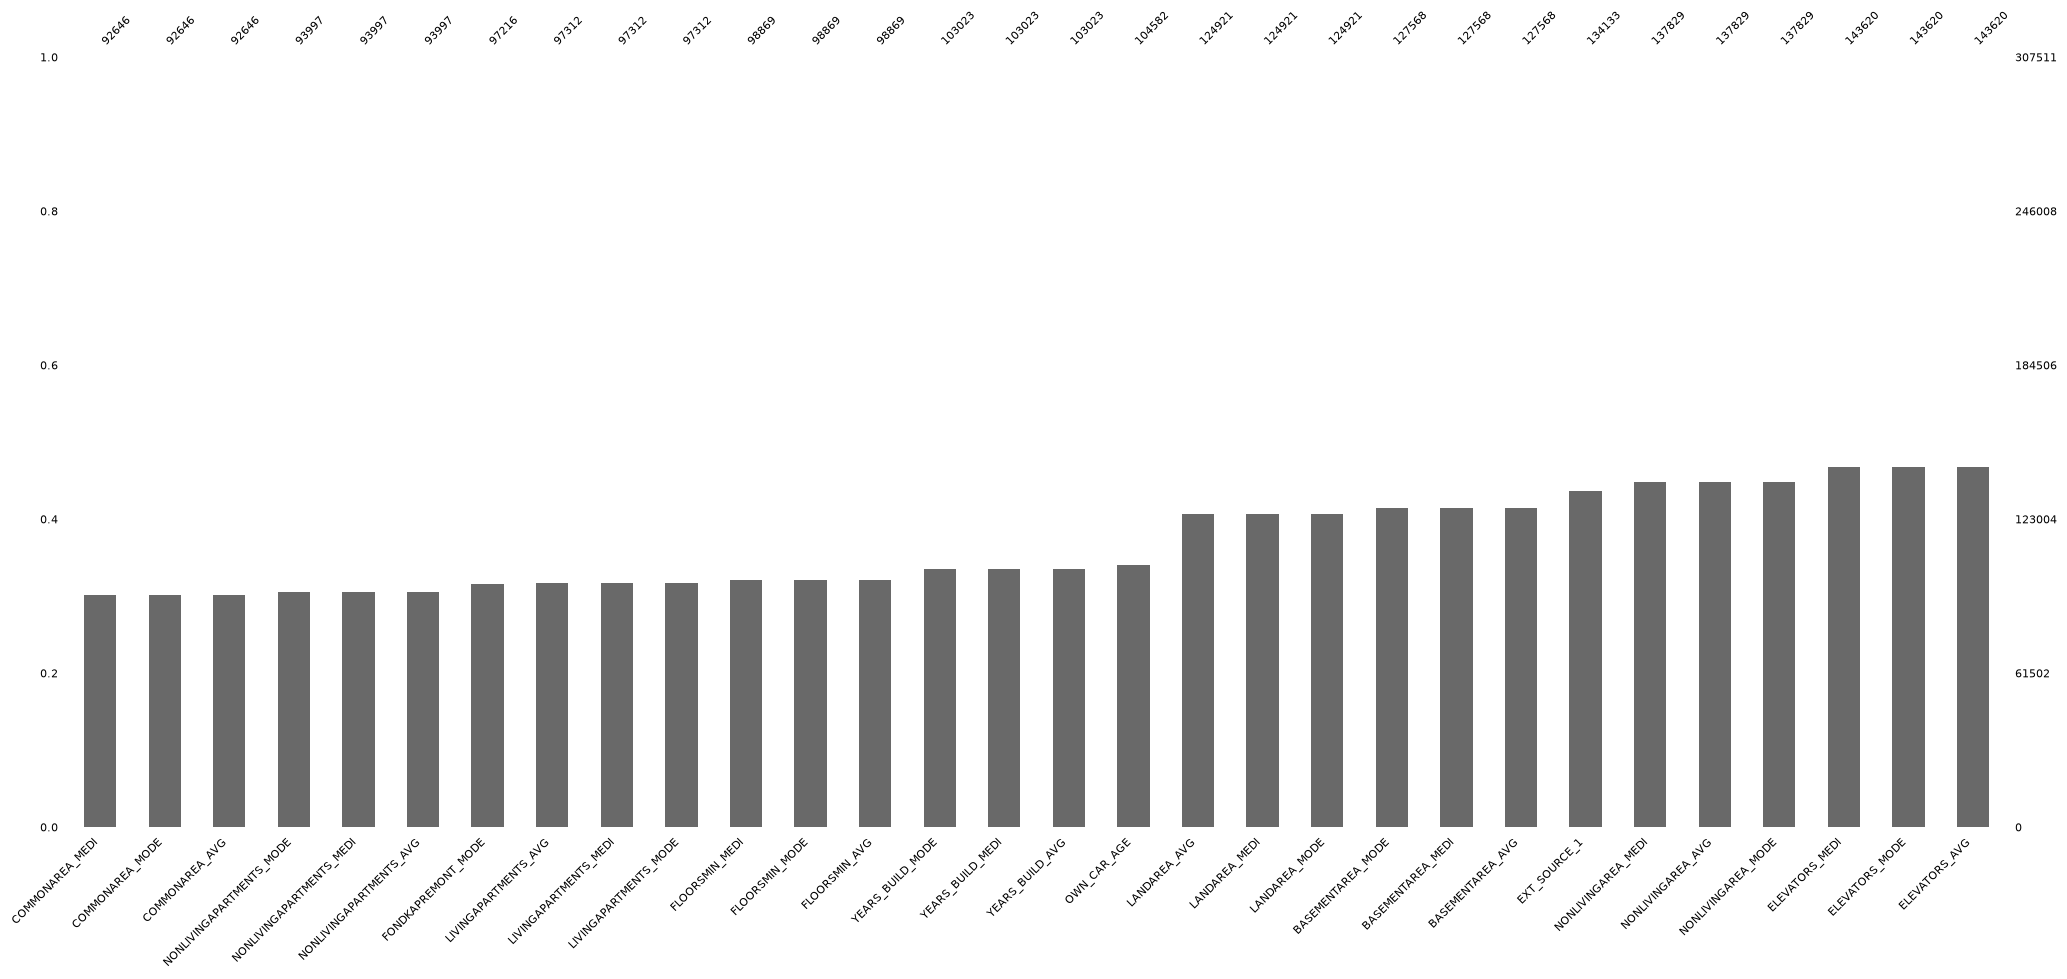

In [7]:
import missingno as mn
mn.bar(df_raw[missing.index[:30]], fontsize=8);

Most of the emptiest columns describe the applicant's **building** (three versions each of 14 measurements). We keep missing values rather than deleting rows: for people with little history, "no data" is itself informative.

In [8]:
# 3. Inconsistent data and units

print('DAYS_ columns are NEGATIVE (days before the application), e.g. DAYS_BIRTH:', df_raw['DAYS_BIRTH'].max(), 'to', df_raw['DAYS_BIRTH'].min())
print('DAYS_EMPLOYED = 365243 (= 1,000 years) :', (df_raw['DAYS_EMPLOYED'] == 365243).sum(), 'rows')
print('CODE_GENDER   = XNA                     :', (df_raw['CODE_GENDER'] == 'XNA').sum(), 'rows')
print('ORGANIZATION_TYPE = XNA                 :', (df_raw['ORGANIZATION_TYPE'] == 'XNA').sum(), 'rows')

df_raw.loc[df_raw['DAYS_EMPLOYED'] == 365243, 'NAME_INCOME_TYPE'].value_counts()

DAYS_ columns are NEGATIVE (days before the application), e.g. DAYS_BIRTH: -7489 to -25229
DAYS_EMPLOYED = 365243 (= 1,000 years) : 55374 rows
CODE_GENDER   = XNA                     : 4 rows
ORGANIZATION_TYPE = XNA                 : 55374 rows


NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64

`DAYS_EMPLOYED = 365243` is a **code**, not a value: it marks pensioners and the unemployed (18% of applicants). Ages and durations are stored as negative day counts, so they are converted to positive years.

In [9]:
# 4. Outliers

df_raw[['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']].describe().T

,count,mean,std,min,25%,50%,75%,max
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,270000.0,513531.0,808650.0,4050000.0
AMT_ANNUITY,307499.0,27108.573909,14493.737315,1615.5,16524.0,24903.0,34596.0,258025.5
AMT_GOODS_PRICE,307233.0,538396.207429,369446.460540,40500.0,238500.0,450000.0,679500.0,4050000.0


One applicant reports an income of 117 million, about 800 times the median (147,150). Outliers are winsorized.

### Corrections log

The original data (`df_raw`) is never changed and every correction is made on a copy (`df`).

In [10]:
df = df_raw.copy()
corrections = []

def correct(column, rows, what):
    corrections.append({'column': column, 'rows changed': int(rows), 'correction': what})

n = (df['DAYS_EMPLOYED'] == 365243).sum()
df['NOT_EMPLOYED'] = (df['DAYS_EMPLOYED'] == 365243).astype(int)          # keep the information as a flag
df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace(365243, np.nan)
correct('DAYS_EMPLOYED', n, '365243 code -> missing, plus NOT_EMPLOYED flag')

for col, code_ in [('CODE_GENDER', 'XNA'), ('ORGANIZATION_TYPE', 'XNA')]:
    n = (df[col] == code_).sum()
    df[col] = df[col].replace(code_, np.nan)
    correct(col, n, f'{code_} placeholder -> missing')

## 4. Exploratory Data Analysis

In [11]:

import plotly.express as px       
import matplotlib.pyplot as plt   
import seaborn as sns             

### Univariate

In [12]:
df['TARGET'].value_counts().to_frame('applications').assign(share=lambda t: t['applications'] / t['applications'].sum())

,applications,share
TARGET,,
0,282686,0.919271
1,24825,0.080729


**8.1% of approved loans defaulted** (24,825 of 307,511). That is today's KPI value when everyone is approved, and the classes are **imbalanced**: a model that always says "will repay" would be 92% accurate and useless. So accuracy is not used to judge models.

In [13]:

fig =  px.histogram(
    data_frame= df.sample(30000, random_state=42),    
    x='AMT_INCOME_TOTAL'
)

fig.update_layout(
    title ='Incomes are heavily skewed: a few very high values stretch the scale',
    yaxis_title='Applicants (sample of 30,000)',
    xaxis_title='Annual income (dataset currency)'
)

fig.show()

# Next steps...
- Use a scaler that is not thrown off by extremes
- Treat outliers (IQR)


In [14]:
def treat_outliers(df:pd.DataFrame,col:str):

    q1= df[col].quantile(.25)
    q3= df[col].quantile(.75)

    iqr = q3-q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    changed = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    df[col] = df[col].clip(lower=lower_bound,upper= upper_bound)
    correct(col, changed, f'capped to IQR bounds [{lower_bound:,.0f}, {upper_bound:,.0f}]')

    return df

In [15]:
for col in ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']:
    treat_outliers(df,col)

pd.DataFrame(corrections)

,column,rows changed,correction
0,DAYS_EMPLOYED,55374,"365243 code -> missing, plus NOT_EMPLOYED flag"
1,CODE_GENDER,4,XNA placeholder -> missing
2,ORGANIZATION_TYPE,55374,XNA placeholder -> missing
3,AMT_INCOME_TOTAL,14035,"capped to IQR bounds [-22,500, 337,500]"
4,AMT_CREDIT,6562,"capped to IQR bounds [-537,975, 1,616,625]"
5,AMT_ANNUITY,7504,"capped to IQR bounds [-10,584, 61,704]"
6,AMT_GOODS_PRICE,14728,"capped to IQR bounds [-423,000, 1,341,000]"


### Bivariate: who defaults, and how many applicants are behind each rate?

Every rate below is shown with its **denominator** (number of applicants), so small groups are not over-read.

In [16]:
df['AGE'] = -df['DAYS_BIRTH'] / 365
df['AGE_BAND'] = pd.cut(df['AGE'], [0, 30, 45, 60, 100], labels=['<30', '30-44', '45-59', '60+'])

def default_rates(by):
    return df.groupby(by, observed=True)['TARGET'].agg(applicants='count', default_rate='mean')

default_rates('NAME_INCOME_TYPE').sort_values('applicants', ascending=False)

,applicants,default_rate
NAME_INCOME_TYPE,,
Working,158774,0.095885
Commercial associate,71617,0.074843
Pensioner,55362,0.053864
State servant,21703,0.057550
Unemployed,22,0.363636
Student,18,0.000000
Businessman,10,0.000000
Maternity leave,5,0.400000


Groups such as *Businessman* (10 applicants) or *Maternity leave* (5) are far too small to draw conclusions from, whatever their rate.

In [17]:
default_rates('AGE_BAND')

,applicants,default_rate
AGE_BAND,,
<30,45021,0.114569
30-44,123714,0.090030
45-59,103197,0.065680
60+,35579,0.049214


### Quantifying thin-file applicants

In [18]:
bureau = pd.read_csv(DATA + 'bureau.csv')
df['THIN_FILE'] = (~df['SK_ID_CURR'].isin(bureau['SK_ID_CURR'])).astype(int)

thin_table = default_rates('THIN_FILE').rename(index={0: 'Has bureau record', 1: 'Thin-file'})
thin_table['share_of_applicants'] = thin_table['applicants'] / thin_table['applicants'].sum()
thin_table

,applicants,default_rate,share_of_applicants
THIN_FILE,,,
Has bureau record,263491,0.077301,0.856851
Thin-file,44020,0.101249,0.143149


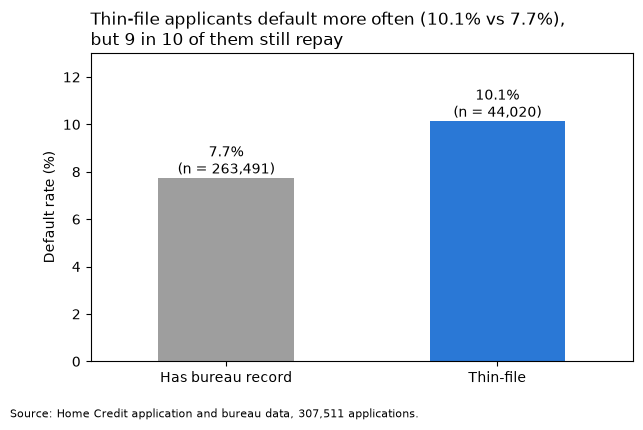

In [19]:
# visual 1

ax = thin_table['default_rate'].mul(100).plot(kind='bar', color=['#9e9e9e', '#2a78d6'], rot=0, figsize=(7, 4))
for i, (rate, n) in enumerate(zip(thin_table['default_rate'], thin_table['applicants'])):
    ax.text(i, rate * 100 + 0.2, f'{rate:.1%}\n(n = {n:,})', ha='center')
ax.set_ylim(0, 13); ax.set_ylabel('Default rate (%)'); ax.set_xlabel('')
ax.set_title('Thin-file applicants default more often (10.1% vs 7.7%),\nbut 9 in 10 of them still repay', loc='left')
plt.figtext(0.01, -0.03, 'Source: Home Credit application and bureau data, 307,511 applications.', fontsize=8)
plt.show()

- **Observed fact:** 44,020 applicants (14.3%) are thin-file; 10.1% of them defaulted against 7.7% of those with a bureau record.
- **Interpretation:** declining every thin-file applicant (the bureau-only rule) turns away about **39,600 people who repaid**, to avoid about 4,500 who did not.
- **Caution:** this is an *association*. Having no bureau record does not *cause* default.

In [20]:
# Some application columns secretly come from the bureau

df.groupby('THIN_FILE')[['EXT_SOURCE_3', 'AMT_REQ_CREDIT_BUREAU_YEAR']].agg(lambda s: s.notna().mean())

,EXT_SOURCE_3,AMT_REQ_CREDIT_BUREAU_YEAR
THIN_FILE,,
0,0.930590,1.000000
1,0.030532,0.056815


`EXT_SOURCE_3` (an external credit score) and the bureau enquiry counts (`AMT_REQ_CREDIT_BUREAU_*`) are almost always **missing for thin-file applicants**. They carry bureau information, so they are grouped with the bureau data (section 6), not with the application form.

### Multivariate

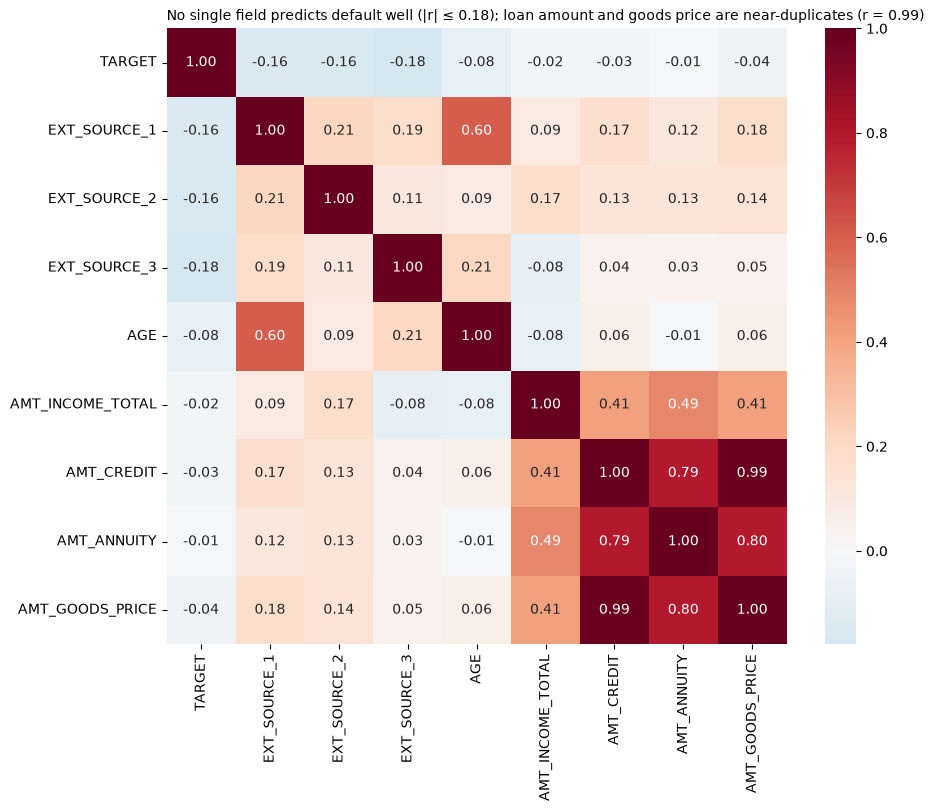

In [21]:
cols_ = ['TARGET', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'AGE', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']

corr = df[cols_].corr()

plt.figure(figsize=(10,8))
sns.heatmap(
    data=corr,
    annot=True, fmt='.2f', cmap='RdBu_r', center=0
)
plt.title('No single field predicts default well (|r| ≤ 0.18); loan amount and goods price are near-duplicates (r = 0.99)', loc='left', fontsize=10);

## 5. Feature engineering: repayment behaviour

**Derived variables** are new columns built from the cleaned data (the third data layer, after *original* and *corrected*).

### From the application form

In [22]:
df['CREDIT_TO_INCOME']  = df['AMT_CREDIT']  / df['AMT_INCOME_TOTAL']    # size of the loan for this person
df['ANNUITY_TO_INCOME'] = df['AMT_ANNUITY'] / df['AMT_INCOME_TOTAL']    # how heavy each repayment is
df['CREDIT_TO_GOODS']   = df['AMT_CREDIT']  / df['AMT_GOODS_PRICE']     # borrowing beyond the goods' price
df['ANNUITY_TO_CREDIT'] = df['AMT_ANNUITY'] / df['AMT_CREDIT']          # roughly 1 / loan term

### From repayment histories (the alternative data)

For each applicant we summarise their history **before the application** over the last **3, 6 and 12 months** and all-time: are payments on time, in full, and is credit used heavily? 

These are the behavioural features, built from Home Credit's repayment records:

| Proposal feature | Built here as |
|---|---|
| payment timeliness | `INST_LATE_RATE`, `INST_DAYS_LATE_MAX`, `POS_PAST_DUE_SHARE`, `POS_DPD_MAX` |
| partial payments | `INST_PARTIAL_RATE`, `CC_BELOW_MIN_SHARE` |
| balance utilisation and volatility | `CC_UTIL_MEAN`, `CC_UTIL_MAX`, `CC_UTIL_VOLATILITY` |
| trends in activity | `INST_LATE_TREND`, `INST_PARTIAL_TREND`, `CC_UTIL_TREND` (last 3 months minus last 12) |
| inflow regularity | no inflow data exists; proxy: `INST_TIMING_IRREGULARITY` (how much payment timing varies) |

In [23]:
def summarise(table, time_col, units_per_month, aggs, prefix):
    '''Per-applicant summary over the last 3, 6, 12 months and all-time.'''
    table = table[table[time_col] < 0]                       # only records BEFORE the application (no leakage)
    parts = []
    for months in [3, 6, 12, None]:
        recent = table if months is None else table[table[time_col] >= -months * units_per_month]
        g = recent.groupby('SK_ID_CURR').agg(**aggs)
        g.columns = [f'{prefix}_{c}_{months}M' if months else f'{prefix}_{c}_ALL' for c in g.columns]
        parts.append(g)
    return pd.concat(parts, axis=1)

In [24]:
# 1. Instalments: were payments on time and in full?

inst = pd.read_csv(DATA + 'installments_payments.csv')

# one row per instalment (one instalment can be paid in several transactions)
inst = inst.groupby(['SK_ID_CURR', 'SK_ID_PREV', 'NUM_INSTALMENT_NUMBER'], as_index=False).agg(
    due_day=('DAYS_INSTALMENT', 'max'), paid_day=('DAYS_ENTRY_PAYMENT', 'max'),
    due=('AMT_INSTALMENT', 'max'), paid=('AMT_PAYMENT', 'sum'))

inst['days_late'] = (inst['paid_day'].fillna(0) - inst['due_day']).clip(lower=0)    # never paid = late until today
inst['late']      = (inst['days_late'] > 0).astype(int)
inst['partial']   = (inst['paid'] < 0.99 * inst['due']).astype(int)
inst['timing']    = inst['paid_day'] - inst['due_day']     # days early (-) or late (+); its spread = how regular the payer is

print('Coverage: instalments per year before the application')
print((-inst['due_day'] // 365 + 1).clip(upper=9).value_counts().sort_index().rename('instalments').to_string())

inst_features = summarise(inst, 'due_day', 30, dict(N=('late', 'size'), LATE_RATE=('late', 'mean'),
                          PARTIAL_RATE=('partial', 'mean'), DAYS_LATE_MAX=('days_late', 'max'),
                          TIMING_IRREGULARITY=('timing', 'std')), 'INST')

# trends: is the applicant getting better or worse recently? (last 3 months minus last 12 months)
inst_features['INST_LATE_TREND']    = inst_features['INST_LATE_RATE_3M']    - inst_features['INST_LATE_RATE_12M']
inst_features['INST_PARTIAL_TREND'] = inst_features['INST_PARTIAL_RATE_3M'] - inst_features['INST_PARTIAL_RATE_12M']
del inst

Coverage: instalments per year before the application
due_day
1.0    3266134
2.0    2681445
3.0    1773294
4.0    1326893
5.0    1112435
6.0    1070372
7.0     988892
8.0     638513
9.0       4016


In [25]:
# 2. POS / cash loans: months past due

pos = pd.read_csv(DATA + 'POS_CASH_balance.csv', usecols=['SK_ID_CURR', 'MONTHS_BALANCE', 'SK_DPD', 'CNT_INSTALMENT_FUTURE'])
pos['past_due'] = (pos['SK_DPD'] > 0).astype(int)

pos_features = summarise(pos, 'MONTHS_BALANCE', 1, dict(PAST_DUE_SHARE=('past_due', 'mean'), DPD_MAX=('SK_DPD', 'max'),
                         FUTURE_INSTALMENTS=('CNT_INSTALMENT_FUTURE', 'mean')), 'POS')
del pos

In [26]:
# 3. Credit cards: how much of the limit is used, and is the minimum paid?

cc = pd.read_csv(DATA + 'credit_card_balance.csv', usecols=['SK_ID_CURR', 'MONTHS_BALANCE', 'AMT_BALANCE', 'AMT_CREDIT_LIMIT_ACTUAL',
                                                     'AMT_PAYMENT_TOTAL_CURRENT', 'AMT_INST_MIN_REGULARITY'])
cc['utilisation'] = cc['AMT_BALANCE'] / cc['AMT_CREDIT_LIMIT_ACTUAL'].replace(0, np.nan)
cc['below_min']   = (cc['AMT_PAYMENT_TOTAL_CURRENT'] < cc['AMT_INST_MIN_REGULARITY']).astype(int)

cc_features = summarise(cc, 'MONTHS_BALANCE', 1, dict(UTIL_MEAN=('utilisation', 'mean'), UTIL_MAX=('utilisation', 'max'),
                        UTIL_VOLATILITY=('utilisation', 'std'), BELOW_MIN_SHARE=('below_min', 'mean')), 'CC')
cc_features['CC_UTIL_TREND'] = cc_features['CC_UTIL_MEAN_3M'] - cc_features['CC_UTIL_MEAN_12M']
del cc

In [27]:
# 4. Previous applications to Home Credit: approved or refused?

prev = pd.read_csv(DATA + 'previous_application.csv', usecols=['SK_ID_CURR', 'NAME_CONTRACT_STATUS', 'DAYS_DECISION'])
prev['approved'] = (prev['NAME_CONTRACT_STATUS'] == 'Approved').astype(int)
prev['refused']  = (prev['NAME_CONTRACT_STATUS'] == 'Refused').astype(int)

prev_features = summarise(prev, 'DAYS_DECISION', 30, dict(N=('approved', 'size'), APPROVED_RATE=('approved', 'mean'),
                          REFUSED_RATE=('refused', 'mean')), 'PREV')
del prev

In [28]:
# 5. Credit bureau: loans at other lenders (used only in feature set C)

bureau['active']        = (bureau['CREDIT_ACTIVE'] == 'Active').astype(int)
bureau['active_debt']   = bureau['AMT_CREDIT_SUM_DEBT'].where(bureau['active'] == 1)
bureau['active_credit'] = bureau['AMT_CREDIT_SUM'].where(bureau['active'] == 1)

bureau_features = bureau[bureau['DAYS_CREDIT'] < 0].groupby('SK_ID_CURR').agg(
    BUR_N=('SK_ID_BUREAU', 'count'), BUR_ACTIVE_N=('active', 'sum'),
    BUR_ACTIVE_DEBT=('active_debt', 'sum'), BUR_ACTIVE_CREDIT=('active_credit', 'sum'),
    BUR_OVERDUE=('AMT_CREDIT_SUM_OVERDUE', 'sum'), BUR_MAX_DAYS_OVERDUE=('CREDIT_DAY_OVERDUE', 'max'),
    BUR_DAYS_SINCE_LAST=('DAYS_CREDIT', 'max'))
bureau_features['BUR_DEBT_RATIO'] = bureau_features['BUR_ACTIVE_DEBT'] / bureau_features['BUR_ACTIVE_CREDIT'].replace(0, np.nan)

# 6. Bureau monthly status: was each outside loan paid on time month by month? (STATUS 1-5 = past due)
bb = pd.read_csv(DATA + 'bureau_balance.csv', dtype={'SK_ID_BUREAU': 'int32', 'MONTHS_BALANCE': 'int16', 'STATUS': 'category'})
bb = bb[bb['MONTHS_BALANCE'] < 0]                                            # only months before the application
bb = bb.merge(bureau[['SK_ID_BUREAU', 'SK_ID_CURR']], on='SK_ID_BUREAU')     # link each month to the applicant
bb['past_due'] = bb['STATUS'].isin(['1', '2', '3', '4', '5']).astype(int)
bb['worst']    = pd.to_numeric(bb['STATUS'], errors='coerce')                 # C (closed) and X (unknown) -> missing

bb_features = bb[bb['MONTHS_BALANCE'] < 0].groupby('SK_ID_CURR').agg(BB_PAST_DUE_SHARE_ALL=('past_due', 'mean'),
                                                                      BB_WORST_STATUS=('worst', 'max'))
bb_features['BB_PAST_DUE_SHARE_12M'] = bb[bb['MONTHS_BALANCE'].between(-12, -1)].groupby('SK_ID_CURR')['past_due'].mean()
bureau_features = bureau_features.join(bb_features)
print(f'bureau_balance rows: {len(bb):,} | applicants with monthly bureau status: {len(bb_features):,}')
del bureau, bb

bureau_balance rows: 23,591,219 | applicants with monthly bureau status: 134,299


In [29]:
# Joining everything into one table: one row per application

behaviour = pd.concat([inst_features, pos_features, cc_features, prev_features], axis=1)
data = df.set_index('SK_ID_CURR').join(behaviour).join(bureau_features)

# a count is 0 (not missing) when someone has no records
count_cols = [c for c in data.columns if c.endswith(('_N_3M', '_N_6M', '_N_12M', '_N_ALL')) or c in ('BUR_N', 'BUR_ACTIVE_N')]
data[count_cols] = data[count_cols].fillna(0)

print(data.shape, '| behavioural features:', behaviour.shape[1], '| bureau features:', bureau_features.shape[1])
print(f"Thin-file applicants with instalment history with Home Credit: {(data.loc[data['THIN_FILE'] == 1, 'INST_N_ALL'] > 0).mean():.1%}")

(307511, 203) | behavioural features: 63 | bureau features: 11
Thin-file applicants with instalment history with Home Credit: 94.6%


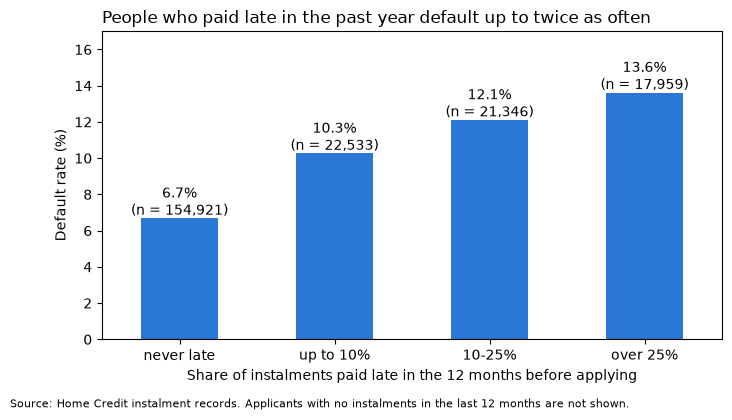

In [30]:
# Visual 2: Does behaviour carry signal?

late = pd.cut(data['INST_LATE_RATE_12M'], [-0.01, 0, 0.1, 0.25, 1], labels=['never late', 'up to 10%', '10-25%', 'over 25%'])
signal = data.groupby(late, observed=True)['TARGET'].agg(applicants='count', default_rate='mean')

ax = signal['default_rate'].mul(100).plot(kind='bar', color='#2a78d6', rot=0, figsize=(8, 4))
for i, (rate, n) in enumerate(zip(signal['default_rate'], signal['applicants'])):
    ax.text(i, rate * 100 + 0.2, f'{rate:.1%}\n(n = {n:,})', ha='center')
ax.set_ylim(0, 17); ax.set_ylabel('Default rate (%)'); ax.set_xlabel('Share of instalments paid late in the 12 months before applying')
ax.set_title('People who paid late in the past year default up to twice as often', loc='left')
plt.figtext(0.01, -0.06, 'Source: Home Credit instalment records. Applicants with no instalments in the last 12 months are not shown.', fontsize=8)
plt.show()

**Observed fact:** default rises steadily from 7% (never late) to 14% (late on over a quarter of instalments). And **94.6% of thin-file applicants** have instalment history with Home Credit, so this behaviour is available exactly for the people the bureau cannot score.

### Telco-type signals

Home Credit also scores applicants on telco data. The public data keeps only a trace of it on the application form, for example `DAYS_LAST_PHONE_CHANGE` (how long the applicant has had the same phone). These columns are already in feature set A.

In [31]:
phone = pd.cut(-data['DAYS_LAST_PHONE_CHANGE'], [-1, 0, 180, 365, 730, 1e5],
               labels=['same day', 'under 6 months', '6-12 months', '1-2 years', 'over 2 years'])
pd.concat({'all applicants': data.groupby(phone, observed=True)['TARGET'].agg(applicants='count', default_rate='mean'),
           'thin-file':      data[data['THIN_FILE'] == 1].groupby(phone[data['THIN_FILE'] == 1], observed=True)['TARGET'].agg(
                                 applicants='count', default_rate='mean')}, axis=1).rename_axis('phone changed')

all applicants               thin-file             
                   applicants default_rate applicants default_rate
phone changed                                                     
same day                37672     0.096650       6359     0.132411
under 6 months          26238     0.091089       3553     0.128342
6-12 months             28710     0.098885       5607     0.115391
1-2 years               57621     0.092970      10002     0.104479
over 2 years           157269     0.067388      18498     0.079306

**Observed fact:** applicants who changed phone recently default more often. Among thin-file applicants, 13% of those who changed phone in the last 6 months defaulted, against 8% of those with the same phone for over 2 years. Phone stability is a small piece of telco data that already carries signal; real telco and mobile-money records would likely carry more (an assumption to test).

## 6. Data preparation for Machine Learning

### Three feature sets

To measure what each data source adds, the same model is trained on three nested sets:

| Set | Contents | Who has this data |
|---|---|---|
| **A** | application form only | any lender |
| **B** | A + repayment behaviour | a lender with its own repayment records |
| **C** | B + bureau data + external scores | a lender that also buys bureau data |

### Data Leakage

Kept out of the model:

- `TARGET` (the answer): using it as an input would hand the model the outcome it is meant to predict.
- `SK_ID_CURR` (an application number): not leakage as such, but it carries no meaning and could create
  fake patterns if IDs were issued in date order.
- History dated **after** the application (the `summarise()` helper keeps only past records).
- **Bureau information hiding in the form** (`EXT_SOURCE_*`, `AMT_REQ_CREDIT_BUREAU_*`): only in set C.
- `CODE_GENDER`: never a model input; kept only to check fairness.

In [32]:
helper_cols    = ['TARGET', 'THIN_FILE', 'AGE', 'AGE_BAND', 'CODE_GENDER']
bureau_inside  = [c for c in data.columns if c.startswith(('EXT_SOURCE', 'AMT_REQ_CREDIT_BUREAU'))]
behaviour_cols = list(behaviour.columns)
bureau_cols    = list(bureau_features.columns) + bureau_inside
application    = [c for c in data.columns if c not in helper_cols + behaviour_cols + bureau_cols]

feature_sets = {'A': application,
                'B': application + behaviour_cols,
                'C': application + behaviour_cols + bureau_cols}
{k: len(v) for k, v in feature_sets.items()}

{'A': 115, 'B': 178, 'C': 198}

### Class Imbalance

Only 8% default. We do **not** use SMOTE or undersampling: they distort the model's probabilities, and a lender needs honest probabilities to set a cut-off. Instead we use metrics that are not fooled by imbalance, a split that keeps 8% defaulters in both parts, and a cut-off chosen by **cost** (section 8).

### Train and target features

In [33]:
from sklearn.model_selection import train_test_split

X = data
y = data['TARGET']

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    stratify=y,
                                                    random_state=42)

thin = (X_test['THIN_FILE'] == 1).to_numpy()          # thin-file applicants in the test set
print(f'Train {len(X_train):,} | Test {len(X_test):,} ({thin.sum():,} thin-file)')

Train 246,008 | Test 61,503 (8,776 thin-file)


The test set (20%) is used **only** to measure results. The data has no application dates, so a split by time (train on older loans, test on newer) is not possible; section 11 discusses this.

**Create pipeline: a Weight-of-Evidence (WoE) scorecard.** This is the classic, transparent credit-scoring method, and the baseline the more complex model must beat. The pipeline has two steps:

1. **WoE transformer**: cut each feature into about 5 bins (equal-sized groups; text columns keep their common values; missing values get their own bin, because a missing history is itself a signal). Each bin is replaced by its **Weight of Evidence** = ln(share of good customers in the bin / share of defaulters in the bin). Positive = safer than average, negative = riskier. Outliers simply fall in the top bin, so no scaling or imputation is needed.
2. **Logistic Regression** on the WoE values.

Features with an **Information Value** (IV, how strongly the bins separate good from bad) below 0.02 are dropped, the usual scorecard rule. All bins and WoE values are learnt from the training data only.

In [34]:
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression

class WoETransformer(BaseEstimator, TransformerMixin):
    # Cut each feature into bins and replace each bin by its Weight of Evidence.
    def __init__(self, n_bins=5, min_share=0.01, min_iv=0.02):
        self.n_bins, self.min_share, self.min_iv = n_bins, min_share, min_iv

    def _bins(self, x, c):
        if c in self.edges_:                                                   # numerical: bin number
            v = pd.to_numeric(x, errors='coerce').astype(float)
            b = pd.Series(np.digitize(v.fillna(0), self.edges_[c]), index=x.index).astype(str)
            return b.where(v.notna(), 'MISSING')
        x = x.astype(object)                                                   # text: common values, rest pooled
        return x.where(x.isin(self.keep_[c]), 'OTHER').where(x.notna(), 'MISSING').astype(str)

    def fit(self, X, y):
        y = pd.Series(np.asarray(y), index=X.index)
        n_bad, n_good = y.sum(), (1 - y).sum()
        self.edges_, self.keep_, self.woe_, self.iv_ = {}, {}, {}, {}
        for c in X.columns:
            if X[c].dtype.kind in 'fiub':
                q = np.nanquantile(X[c].astype(float), np.linspace(0, 1, self.n_bins + 1)[1:-1])
                self.edges_[c] = np.unique(q[~np.isnan(q)])
            else:
                share = X[c].value_counts(normalize=True)
                self.keep_[c] = list(share[share >= self.min_share].index)
            t = y.groupby(self._bins(X[c], c)).agg(['size', 'sum'])
            p_good = (t['size'] - t['sum'] + 0.5) / n_good                    # +0.5 avoids log(0) in tiny bins
            p_bad  = (t['sum'] + 0.5) / n_bad
            woe = np.log(p_good / p_bad)
            self.woe_[c], self.iv_[c] = woe.to_dict(), float(((p_good - p_bad) * woe).sum())
        self.selected_ = [c for c in X.columns if self.iv_[c] >= self.min_iv]
        return self

    def transform(self, X):                                                    # a bin never seen in training -> 0 (neutral)
        return pd.DataFrame({c: self._bins(X[c], c).map(self.woe_[c]).fillna(0).astype(float)
                             for c in self.selected_}, index=X.index)

def scorecard():
    return Pipeline([('woe', WoETransformer()),
                     ('model', LogisticRegression(max_iter=1000))])

## 7. Model Training and Comparison with the Bureau-only Rule

Evaluate a classifier

- **ROC-AUC**: how well the model ranks risky applicants above safe ones (0.5 = guessing, 1 = perfect). Not fooled by imbalance, and independent of the cut-off.
- Precision, recall and the KPI (default rate among approved loans) depend on the cut-off, so they come in section 8.
- Accuracy: **not used** (class imbalance).

Every AUC gets a **95% confidence interval** from a bootstrap: the test set is resampled 500 times and the AUC recomputed each time.

In [35]:
from sklearn.metrics import roc_auc_score
pd.set_option('display.float_format','{:.3f}'.format)     # model differences are small: 3 decimals

def auc_ci(y_true, p, n=500):
    y_true, p = np.asarray(y_true), np.asarray(p)
    rng, aucs = np.random.default_rng(42), []
    for _ in range(n):
        i = rng.integers(0, len(y_true), len(y_true))
        aucs.append(roc_auc_score(y_true[i], p[i]))
    return f'{roc_auc_score(y_true, p):.3f} ({np.percentile(aucs, 2.5):.3f}-{np.percentile(aucs, 97.5):.3f})'

results = {}
def evaluate(name, p):
    results[name] = {'AUC, all applicants (95% CI)': auc_ci(y_test, p), 'AUC, thin-file (95% CI)': auc_ci(y_test[thin], p[thin])}
    return pd.DataFrame(results).T

### Baseline: the WoE scorecard

The scorecard is trained on each of the three feature sets, so we can see what each data source adds even with the simplest credible model.

In [36]:
sc_models, sc_preds = {}, {}
for name in ['A', 'B', 'C']:
    cols = feature_sets[name]
    sc_models[name] = scorecard().fit(X_train[cols], y_train)    # Training
    sc_preds[name]  = sc_models[name].predict_proba(X_test[cols])[:, 1]
    evaluate(f'WoE scorecard (set {name})', sc_preds[name])

pd.DataFrame(results).T

,"AUC, all applicants (95% CI)","AUC, thin-file (95% CI)"
WoE scorecard (set A),0.675 (0.667-0.682),0.679 (0.661-0.698)
WoE scorecard (set B),0.705 (0.698-0.713),0.710 (0.692-0.729)
WoE scorecard (set C),0.756 (0.749-0.762),0.730 (0.712-0.748)


In [37]:
# Which features separate good from bad customers most? (Information Value, set B scorecard)
# Rule of thumb: IV < 0.02 useless (dropped), 0.02-0.1 weak, 0.1-0.3 medium, > 0.3 strong

woe_step = sc_models['B'].named_steps['woe']
iv = pd.Series(woe_step.iv_).sort_values(ascending=False)
print(f"{len(woe_step.selected_)} of {len(iv)} features kept (IV >= 0.02)")
iv.head(10).rename('information value').to_frame()

69 of 178 features kept (IV >= 0.02)


,information value
DAYS_EMPLOYED,0.108
DAYS_BIRTH,0.085
OCCUPATION_TYPE,0.082
CC_UTIL_MAX_12M,0.081
CC_UTIL_MAX_6M,0.080
CC_UTIL_MAX_3M,0.077
CC_UTIL_MEAN_3M,0.072
CC_UTIL_MEAN_12M,0.068
CC_UTIL_MEAN_6M,0.067
INST_DAYS_LATE_MAX_12M,0.064


In [38]:
# The scorecard as points: 600 points = odds of 50 good : 1 bad, and every 20 points doubles the odds
factor = 20 / np.log(2)
offset = 600 - factor * np.log(50)
to_points = lambda pd_: offset + factor * np.log((1 - pd_) / pd_)

# points each bin adds for the strongest behavioural feature
lr_step = sc_models['B'].named_steps['model']
feature = [c for c in iv.index if c in behaviour_cols][0]
coef = lr_step.coef_[0][woe_step.selected_.index(feature)]
points = pd.Series({b: -coef * w * factor for b, w in woe_step.woe_[feature].items()}).round(0)
print(f'Points added by {feature} (bins numbered from lowest to highest value; MISSING = no record):')
print(points.to_string())
print(f'\nTest-set scores: median {np.median(to_points(sc_preds["B"])):.0f}, 10th-90th percentile '
      f'{np.percentile(to_points(sc_preds["B"]), 10):.0f}-{np.percentile(to_points(sc_preds["B"]), 90):.0f}')

Points added by CC_UTIL_MAX_12M (bins numbered from lowest to highest value; MISSING = no record):
1          2.000
2         -1.000
3         -4.000
MISSING    0.000

Test-set scores: median 565, 10th-90th percentile 536-590


### Main model: LightGBM (Boosting)

Types of ensemble models

1. Stacking
2. **Boosting**  ~ LightGBM
3. Bagging      ~ Random Forest
4. Voting

LightGBM needs **no pipeline**: it handles missing values and text categories itself, and outliers do not affect trees. That matters here, because a missing history is itself a signal.

In [39]:
import lightgbm as lgb

def lightgbm(feature_set):
    cols = feature_sets[feature_set]
    to_lgb = lambda X: X[cols].astype({c: 'category' for c in cols if X[c].dtype.kind not in 'fiub'})
    model = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                               colsample_bytree=0.5, subsample=0.8, subsample_freq=1, reg_lambda=5,
                               importance_type='gain', random_state=42, verbose=-1)
    model.fit(to_lgb(X_train), y_train)
    return model, model.predict_proba(to_lgb(X_test))[:, 1]

preds, models = {}, {}
for name in ['A', 'B', 'C']:
    models[name], preds[name] = lightgbm(name)
    evaluate(f'LightGBM (set {name})', preds[name])

pd.DataFrame(results).T

,"AUC, all applicants (95% CI)","AUC, thin-file (95% CI)"
WoE scorecard (set A),0.675 (0.667-0.682),0.679 (0.661-0.698)
WoE scorecard (set B),0.705 (0.698-0.713),0.710 (0.692-0.729)
WoE scorecard (set C),0.756 (0.749-0.762),0.730 (0.712-0.748)
LightGBM (set A),0.719 (0.712-0.726),0.733 (0.715-0.750)
LightGBM (set B),0.749 (0.743-0.756),0.767 (0.750-0.783)
LightGBM (set C),0.788 (0.782-0.794),0.777 (0.762-0.794)


In [40]:
# Summary: both models x three feature sets (AUC on the test set)

summary = pd.DataFrame({(group, model): {s: roc_auc_score(y_test[mask], p[s][mask]) for s in 'ABC'}
                        for group, mask in [('all applicants', np.ones(len(y_test), bool)), ('thin-file', thin)]
                        for model, p in [('WoE scorecard', sc_preds), ('LightGBM', preds)]}).T
summary.columns = ['A: application', 'B: + behaviour', 'C: + bureau']
summary

A: application  B: + behaviour  C: + bureau
all applicants WoE scorecard           0.675           0.705        0.756
               LightGBM                0.719           0.749        0.788
thin-file      WoE scorecard           0.679           0.710        0.730
               LightGBM                0.733           0.767        0.777

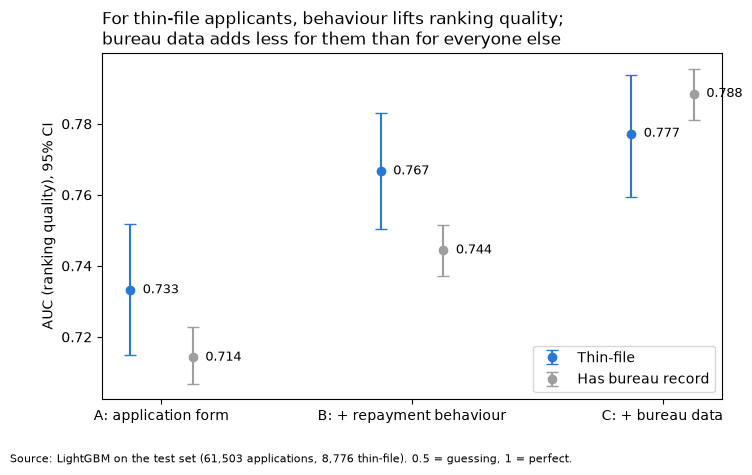

In [41]:
# Visual 3: what does each data source add for thin-file applicants?

fig, ax = plt.subplots(figsize=(8, 4.5))
for j, (label, mask, colour) in enumerate([('Thin-file', thin, '#2a78d6'), ('Has bureau record', ~thin, '#9e9e9e')]):
    for i, name in enumerate(['A', 'B', 'C']):
        yt, p = y_test.to_numpy()[mask], preds[name][mask]
        rng, aucs = np.random.default_rng(42), []
        for _ in range(300):
            k = rng.integers(0, len(yt), len(yt)); aucs.append(roc_auc_score(yt[k], p[k]))
        auc, lo, hi = roc_auc_score(yt, p), np.percentile(aucs, 2.5), np.percentile(aucs, 97.5)
        x = i + (j - 0.5) * 0.25
        ax.errorbar(x, auc, yerr=[[auc - lo], [hi - auc]], fmt='o', color=colour, capsize=4, label=label if i == 0 else None)
        ax.text(x + 0.05, auc, f'{auc:.3f}', va='center', fontsize=9)
ax.set_xticks([0, 1, 2], ['A: application form', 'B: + repayment behaviour', 'C: + bureau data'])
ax.set_ylabel('AUC (ranking quality), 95% CI')
ax.set_title('For thin-file applicants, behaviour lifts ranking quality;\nbureau data adds less for them than for everyone else', loc='left')
ax.legend(loc='lower right')
plt.figtext(0.01, -0.03, 'Source: LightGBM on the test set (61,503 applications, 8,776 thin-file). 0.5 = guessing, 1 = perfect.', fontsize=8)
plt.show()

In [42]:
# Is the gain real? Paired bootstrap of the AUC difference on the same applicants

def gain(a, b, mask, p=preds, n=500):
    yt, pa, pb = y_test.to_numpy()[mask], p[a][mask], p[b][mask]
    rng, d = np.random.default_rng(42), []
    for _ in range(n):
        k = rng.integers(0, len(yt), len(yt))
        d.append(roc_auc_score(yt[k], pb[k]) - roc_auc_score(yt[k], pa[k]))
    return f'{roc_auc_score(yt, pb) - roc_auc_score(yt, pa):+.3f} (95% CI {np.percentile(d, 2.5):+.3f} to {np.percentile(d, 97.5):+.3f})'

print('Thin-file   A -> B (add behaviour):', gain('A', 'B', thin))
print('Thin-file   B -> C (add bureau)   :', gain('B', 'C', thin))
print('Bureau-file B -> C (add bureau)   :', gain('B', 'C', ~thin))
print('Scorecard, thin-file A -> B       :', gain('A', 'B', thin, p=sc_preds))

Thin-file   A -> B (add behaviour): +0.033 (95% CI +0.022 to +0.046)
Thin-file   B -> C (add bureau)   : +0.011 (95% CI +0.001 to +0.020)
Bureau-file B -> C (add bureau)   : +0.044 (95% CI +0.039 to +0.050)
Scorecard, thin-file A -> B       : +0.031 (95% CI +0.019 to +0.041)


- **Observed:** for thin-file applicants, adding repayment behaviour improves ranking clearly (the interval is well above zero).
- **Interpretation:** Home Credit's own repayment records do for thin-file applicants much of what a bureau record does for everyone else (tested directly below). Thin-file applicants have no bureau loans, so set C can only help them through the external scores (`EXT_SOURCE`), which a lender would have to buy and cannot inspect. That gain (+0.011) is a quarter of what bureau data adds for everyone else (+0.044).
- **The finding does not depend on the model:** the simple WoE scorecard shows the same thin-file gain from behaviour (+0.031) as LightGBM (+0.033).
- **Simple vs complex:** LightGBM ranks better than the scorecard on every set, by 0.03-0.06 AUC (thin-file, set B: 0.767 vs 0.710). The scorecard's 5 bins per feature and straight-line combination cannot capture how features combine, so the extra complexity of LightGBM earns its place. The scorecard is kept as the **transparent fallback**: every applicant's score is a sum of points a loan officer can check by hand.

### Head-to-head: behaviour vs bureau records on the same people

The comparison above is indirect (different people, nested sets). A cleaner test uses only test applicants who have **both** repayment behaviour **and** a bureau record, and asks: *on the same people, which ranks risk better, behaviour or bureau records?* Two extra LightGBM models are trained. The external scores (`EXT_SOURCE_*`) are left out of both, so that records are compared with records.

In [43]:
bureau_records = [c for c in bureau_cols if not c.startswith('EXT_SOURCE')]
feature_sets['A+bureau'] = application + bureau_records                     # form + bureau records
feature_sets['B+bureau'] = application + behaviour_cols + bureau_records    # form + behaviour + bureau records
for name in ['A+bureau', 'B+bureau']:
    models[name], preds[name] = lightgbm(name)

both = (~thin) & (X_test['INST_N_ALL'] > 0).to_numpy()       # has bureau record AND repayment history
print(f'Test applicants with both kinds of record: {both.sum():,}\n')
h2h = pd.Series({'Application form only':          auc_ci(y_test[both], preds['A'][both]),
                 'Form + behaviour':                auc_ci(y_test[both], preds['B'][both]),
                 'Form + bureau records':           auc_ci(y_test[both], preds['A+bureau'][both]),
                 'Form + behaviour + bureau records': auc_ci(y_test[both], preds['B+bureau'][both])},
                name='AUC (95% CI)').to_frame()
print(h2h.to_string(), '\n')
print('Behaviour minus bureau records      :', gain('A+bureau', 'B', both))
print('Adding bureau records to behaviour  :', gain('B', 'B+bureau', both))

Test applicants with both kinds of record: 50,023

                                          AUC (95% CI)
Application form only              0.715 (0.706-0.722)
Form + behaviour                   0.745 (0.737-0.753)
Form + bureau records              0.740 (0.732-0.747)
Form + behaviour + bureau records  0.761 (0.753-0.768) 

Behaviour minus bureau records      : +0.006 (95% CI -0.001 to +0.011)
Adding bureau records to behaviour  : +0.016 (95% CI +0.012 to +0.020)


- **Observed:** on the same 50,023 people, behaviour alone (0.745) ranks risk **about as well as** bureau records alone (0.740). The difference, +0.006, is too small to call a winner (its interval includes zero). The pipeline, with fuller features, finds the same tie the other way round (0.743 vs 0.748, also not significant).
- Using both is best (0.761): bureau records add +0.016 on top of behaviour, so the two sources overlap but are not identical.
- **Interpretation:** this is the most direct evidence for the project's question. Where a lender has an applicant's repayment behaviour, it can rank risk about as well as if it had bought a bureau record. That is what makes lending to thin-file applicants possible.

## 8. From scores to decisions: business cost and sensitivity

A score only helps if it changes who is approved. The two errors have **different costs**:

| Error | What happens | Cost to a lender |
|---|---|---|
| Approve someone who defaults | loan not repaid | **high**: the unpaid loan |
| Decline someone who would have repaid | customer lost | **lower**: the interest and fees not earned |

**Assumption (each lender should set its own):** a defaulted loan costs **5 times** as much as a lost good customer. With honest probabilities, it then pays to decline anyone whose probability of default is above **1 / (1 + 5) ≈ 17%**.

First, are the probabilities honest? Compare predicted and actual default rates in ten score bands:

In [44]:
p_final = preds['C']                     # LightGBM, set C: bureau data is used where it exists
bands = pd.qcut(p_final, 10, labels=range(1, 11))
pd.DataFrame({'predicted': p_final, 'actual': y_test.to_numpy()}).groupby(bands, observed=True).mean().T

,1,2,3,4,5,6,7,8,9,10
predicted,0.011,0.018,0.024,0.031,0.041,0.053,0.070,0.097,0.147,0.310
actual,0.008,0.016,0.025,0.029,0.043,0.051,0.076,0.099,0.147,0.314


Predicted and actual rates agree band by band, so the probabilities can be used as probabilities.

In [45]:
from sklearn.metrics import classification_report

def outcome(approve, label):
    '''Results per 1,000 applicants for an approval rule.'''
    yt = y_test.to_numpy()
    per_k = 1000 / len(yt)
    return {'policy': label,
            'approval rate': approve.mean(),
            'KPI: default rate among approved': yt[approve].mean(),
            'thin-file applicants approved': approve[thin].mean(),
            'defaulters approved (per 1,000)': (approve & (yt == 1)).sum() * per_k,
            'good customers declined (per 1,000)': (~approve & (yt == 0)).sum() * per_k}

def cost(row, ratio):        # cost units: 1 = one lost good customer
    return ratio * row['defaulters approved (per 1,000)'] + row['good customers declined (per 1,000)']

threshold = 1 / (1 + 5)
policies = pd.DataFrame([
    outcome(np.ones(len(y_test), bool), 'Approve everyone'),
    outcome(~thin, 'Bureau-only rule: decline all thin-file'),
    outcome(p_final < threshold, 'Model: decline if PD >= 17%'),
]).set_index('policy')
policies['expected cost per 1,000 (5:1)'] = policies.apply(cost, axis=1, ratio=5)
policies.T

policy,Approve everyone,Bureau-only rule: decline all thin-file,Model: decline if PD >= 17%
approval rate,1.000,0.857,0.879
KPI: default rate among approved,0.081,0.077,0.052
thin-file applicants approved,1.000,0.000,0.824
"defaulters approved (per 1,000)",80.728,66.257,45.640
"good customers declined (per 1,000)",0.000,128.221,86.142
"expected cost per 1,000 (5:1)",403.639,459.506,314.342


**In business terms (per 1,000 applicants, 5:1 cost assumption):** the model approves more applicants than the bureau-only rule, *including* most thin-file applicants, while lowering the default rate among approved loans. It turns away fewer good customers and lets through fewer defaulters, so the expected cost falls.

These are **forecast** benefits measured on historical test data. No lender has observed them yet; a pilot on new applicants would confirm them.

In [46]:
print(classification_report(y_test, (p_final >= threshold).astype(int), target_names=['repaid', 'defaulted']))

              precision    recall  f1-score   support

      repaid       0.95      0.91      0.93     56538
   defaulted       0.29      0.43      0.35      4965

    accuracy                           0.87     61503
   macro avg       0.62      0.67      0.64     61503
weighted avg       0.89      0.87      0.88     61503



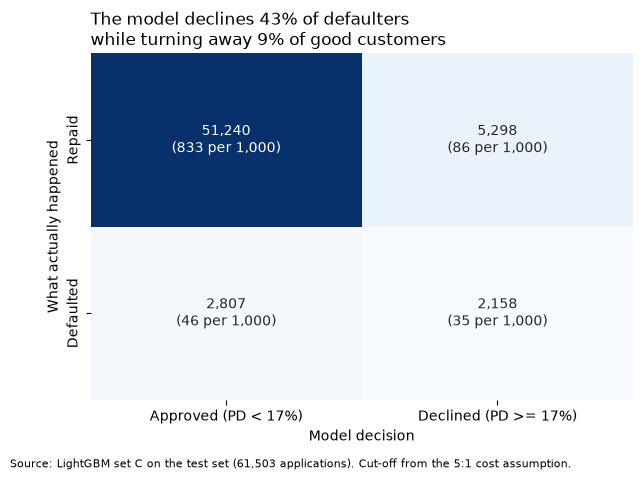

In [47]:
# Confusion matrix: the four possible outcomes of a decision, per 1,000 applicants
from sklearn.metrics import confusion_matrix

y_pred = (p_final >= threshold).astype(int)             # 1 = decline (predicted to default)
cm = confusion_matrix(y_test, y_pred)                   # rows: actual repaid / defaulted; columns: approved / declined
per_k = cm / cm.sum() * 1000
labels = np.array([[f'{n:,}\n({k:.0f} per 1,000)' for n, k in zip(rn, rk)] for rn, rk in zip(cm, per_k)])

caught = cm[1, 1] / cm[1].sum()
lost   = cm[0, 1] / cm[0].sum()
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(per_k, annot=labels, fmt='', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['Approved (PD < 17%)', 'Declined (PD >= 17%)'], yticklabels=['Repaid', 'Defaulted'])
ax.set_xlabel('Model decision'); ax.set_ylabel('What actually happened')
ax.set_title(f'The model declines {caught:.0%} of defaulters\nwhile turning away {lost:.0%} of good customers', loc='left')
plt.figtext(0.01, -0.04, f'Source: LightGBM set C on the test set ({cm.sum():,} applications). Cut-off from the 5:1 cost assumption.', fontsize=8)
plt.show()

How to read the four cells (each is an outcome for a lender):

| Cell | Meaning | Business effect |
|---|---|---|
| Repaid, approved (**true negative**) | good loan made | earns interest |
| Defaulted, declined (**true positive**) | bad loan avoided | saves the loan amount |
| Repaid, declined (**false positive**) | good customer turned away | lost interest and fees |
| Defaulted, approved (**false negative**) | bad loan made | loses the loan amount (the costly error) |

The bottom-left cell divided by the whole left column is the KPI (default rate among approved loans).

For "defaulted", **recall** (0.43) is the share of defaulters the model declines, and **precision** (0.29) is the share of declined applicants who would really have defaulted. Precision looks low, but with only 8% defaulters, the model declines 43% of them while turning away only 9% of good applicants, which is worth it under the cost assumption.

### Sensitivity to two assumptions

1. **The cost ratio.** We assumed 5:1. What if a default costs only 3 times a lost customer, or 10 times?
2. **The share of thin-file applicants.** It is 14% in this data, but a lender serving mobile-money users might see 50% or more.

In [48]:
rows = []
for ratio in [3, 5, 10]:
    approve = p_final < 1 / (1 + ratio)
    r = outcome(approve, f'{ratio}:1')
    r['cut-off (PD)'] = 1 / (1 + ratio)
    r['cost saving vs bureau-only rule'] = 1 - cost(r, ratio) / cost(policies.loc['Bureau-only rule: decline all thin-file'], ratio)
    rows.append(r)
sensitivity = pd.DataFrame(rows).set_index('policy')
sensitivity[['cut-off (PD)', 'approval rate', 'KPI: default rate among approved', 'thin-file applicants approved', 'cost saving vs bureau-only rule']]

,cut-off (PD),approval rate,KPI: default rate among approved,thin-file applicants approved,cost saving vs bureau-only rule
policy,,,,,
3:1,0.250,0.940,0.063,0.912,0.343
5:1,0.167,0.879,0.052,0.824,0.316
10:1,0.091,0.735,0.038,0.642,0.383


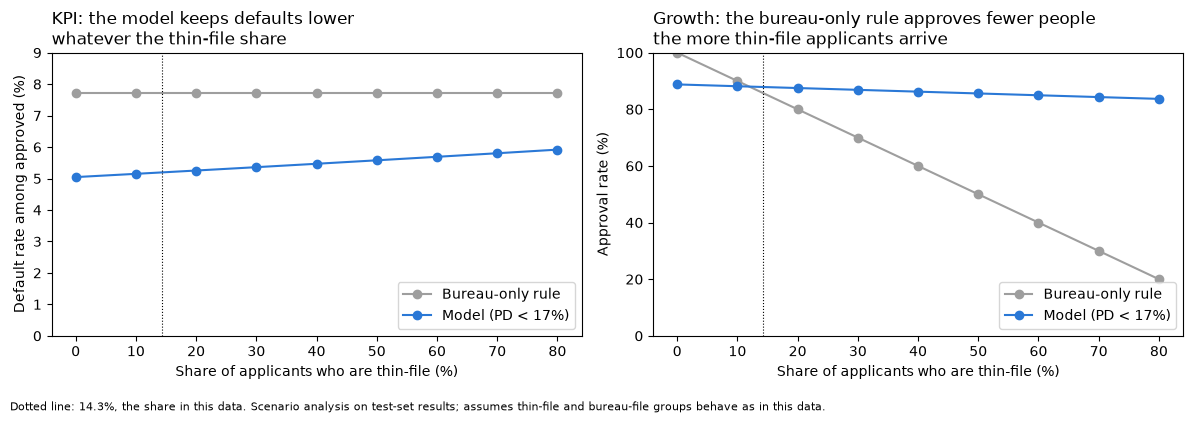

In [49]:
# Visual 4: the KPI across a range of thin-file shares

yt = y_test.to_numpy()
approve = p_final < threshold
def mix(thin_share, approve):
    '''Default rate among approved loans if the applicant pool had this share of thin-file applicants.'''
    d_thin,  a_thin  = yt[thin  & approve].sum(), (thin  & approve).sum() / thin.sum()
    d_thick, a_thick = yt[~thin & approve].sum(), (~thin & approve).sum() / (~thin).sum()
    bad  = thin_share * d_thin / thin.sum() + (1 - thin_share) * d_thick / (~thin).sum()
    good = thin_share * a_thin + (1 - thin_share) * a_thick
    return bad / good, good

shares = np.linspace(0, 0.8, 9)
model_kpi    = [mix(s, approve)[0] for s in shares]
model_appr   = [mix(s, approve)[1] for s in shares]
current_kpi  = [yt[~thin].mean()] * len(shares)                   # the bureau-only rule approves only bureau-file applicants
current_appr = [1 - s for s in shares]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(shares * 100, np.array(current_kpi) * 100, 'o-', color='#9e9e9e', label='Bureau-only rule')
axes[0].plot(shares * 100, np.array(model_kpi) * 100, 'o-', color='#2a78d6', label='Model (PD < 17%)')
axes[0].set_ylabel('Default rate among approved (%)'); axes[0].set_ylim(0, 9)
axes[0].set_title('KPI: the model keeps defaults lower\nwhatever the thin-file share', loc='left')
axes[1].plot(shares * 100, np.array(current_appr) * 100, 'o-', color='#9e9e9e', label='Bureau-only rule')
axes[1].plot(shares * 100, np.array(model_appr) * 100, 'o-', color='#2a78d6', label='Model (PD < 17%)')
axes[1].set_ylabel('Approval rate (%)'); axes[1].set_ylim(0, 100)
axes[1].set_title('Growth: the bureau-only rule approves fewer people\nthe more thin-file applicants arrive', loc='left')
for ax in axes:
    ax.set_xlabel('Share of applicants who are thin-file (%)'); ax.axvline(14.3, color='k', lw=0.8, ls=':'); ax.legend()
plt.figtext(0.01, -0.04, 'Dotted line: 14.3%, the share in this data. Scenario analysis on test-set results; assumes thin-file and bureau-file groups behave as in this data.', fontsize=8)
plt.tight_layout(); plt.show()

**The recommendation holds under both assumptions.**

- **Cost ratio:** at every ratio tested the model costs 31-38% less than the bureau-only rule. At 3:1 and 5:1 it also approves more people; at 10:1 it becomes stricter (74% approved) but still approves 64% of thin-file applicants, whom the bureau-only rule declines entirely.
- **Thin-file share:** the model keeps defaults lower at every share. Below about 12% thin-file, the bureau-only rule approves slightly more people, at a higher default rate. Above that, it approves fewer and fewer, while the model stays near 84-89%.

## 9. Model Explanation and Fairness Check

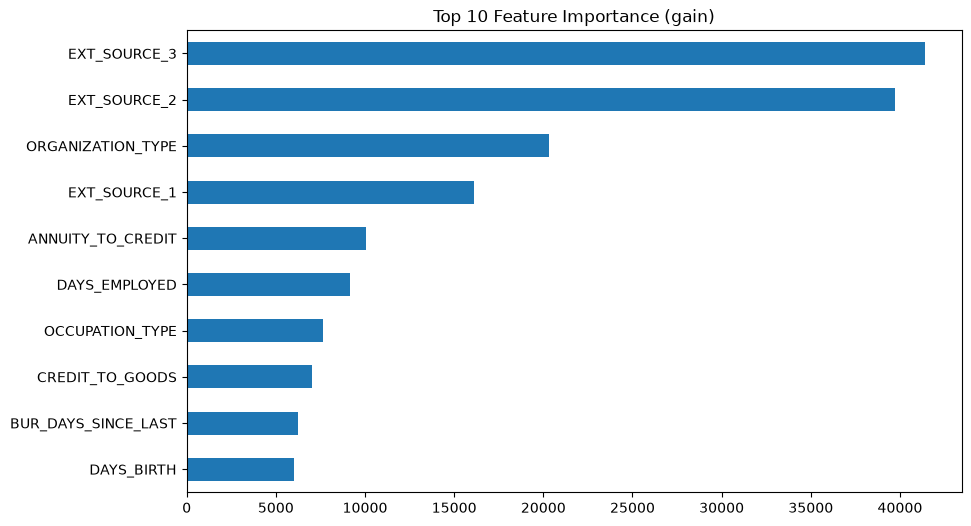

In [50]:
# feature importance

final = models['C']
importance = pd.DataFrame(final.feature_importances_,
                          columns=['importance'],
                          index=final.feature_name_)

importance.sort_values(by='importance',ascending=True).tail(10).plot(kind='barh',figsize=(10,6),title='Top 10 Feature Importance (gain)', legend=False);

### Explaining one decision

LightGBM can split each prediction into the contribution of every feature (**SHAP values**). The largest positive contributions are the applicant's **reasons**, which a lender can give when declining.

In [51]:
cols = feature_sets['C']
X_test_lgb = X_test[cols].astype({c: 'category' for c in cols if X_test[c].dtype.kind not in 'fiub'})

applicant = X_test.index[np.argmax(thin & (p_final >= threshold))]       # a declined thin-file applicant
contrib = pd.Series(final.predict_proba(X_test_lgb.loc[[applicant]], pred_contrib=True)[0, :-1], index=cols)
reasons = contrib.sort_values(ascending=False).head(3)

print(f'Applicant {applicant}: probability of default {p_final[X_test.index.get_loc(applicant)]:.1%} -> decline')
pd.DataFrame({'reason': reasons.index, "applicant's value": X_test.loc[applicant, reasons.index].values,
              'pushes risk up by': reasons.values.round(3)})

Applicant 272065: probability of default 40.7% -> decline


,reason,applicant's value,pushes risk up by
0,EXT_SOURCE_2,0.224,0.573
1,ANNUITY_TO_CREDIT,0.079,0.317
2,PREV_REFUSED_RATE_ALL,0.600,0.284


### Fairness

For each group: does the model rank risk equally well (AUC), and how often is the group approved? The **four-fifths rule** flags any group approved at less than 80% of the best group's rate. Gender was never a model input.

In [52]:
check = X_test[['CODE_GENDER', 'AGE_BAND', 'NAME_EDUCATION_TYPE']].copy()
check['y'], check['p'], check['approved'] = y_test, p_final, p_final < threshold

rows = []
for col in ['CODE_GENDER', 'AGE_BAND', 'NAME_EDUCATION_TYPE']:
    for group, g in check.groupby(col, observed=True):
        if len(g) > 500:              # small groups are not reported (unreliable, and could identify people)
            rows.append({'attribute': col, 'group': group, 'applicants': len(g), 'default rate': g['y'].mean(),
                         'AUC': roc_auc_score(g['y'], g['p']), 'approval rate': g['approved'].mean()})
fair = pd.DataFrame(rows)
fair['vs best group'] = fair['approval rate'] / fair.groupby('attribute')['approval rate'].transform('max')
fair

,attribute,group,applicants,default rate,AUC,approval rate,vs best group
0,CODE_GENDER,F,40561,0.070,0.782,0.898,1.000
1,CODE_GENDER,M,20940,0.102,0.788,0.842,0.938
2,AGE_BAND,<30,8866,0.113,0.761,0.788,0.816
3,AGE_BAND,30-44,24740,0.088,0.796,0.855,0.886
4,AGE_BAND,45-59,20642,0.069,0.781,0.916,0.948
5,AGE_BAND,60+,7255,0.050,0.747,0.966,1.000
6,NAME_EDUCATION_TYPE,Higher education,15061,0.052,0.784,0.944,1.000
7,NAME_EDUCATION_TYPE,Incomplete higher,1988,0.079,0.770,0.871,0.923
8,NAME_EDUCATION_TYPE,Lower secondary,791,0.104,0.775,0.829,0.879
9,NAME_EDUCATION_TYPE,Secondary / secondary special,43623,0.090,0.783,0.857,0.909


- The model ranks risk about **equally well in every group** (similar AUC).
- Approval rates differ mainly where default rates differ. **Under-30s** are approved at about 0.8× the rate of over-60s, close to the four-fifths line, because they default about twice as often. A lender using the model should monitor approvals by age group.

## 10. Decision aid and saved model

The **decision aid** is a one-page table a lender's staff can use without the model's code: each risk band, the share of applicants in it, the default rate seen in that band, and the recommended action.

In [53]:
band_edges = [0, 0.05, 0.10, threshold, 0.30, 1]
band_names = ['1 Very low', '2 Low', '3 Medium', '4 High', '5 Very high']
band = pd.cut(p_final, band_edges, labels=band_names)

decision_aid = pd.DataFrame({'band': band, 'default': y_test.to_numpy(), 'thin': thin}).groupby('band', observed=True).agg(
    applicants=('default', 'size'), default_rate=('default', 'mean'), thin_file_share=('thin', 'mean'))
decision_aid['share of applicants'] = decision_aid['applicants'] / decision_aid['applicants'].sum()
decision_aid['probability of default'] = ['under 5%', '5-10%', f'10-{threshold:.0%}', f'{threshold:.0%}-30%', 'over 30%']
decision_aid['action'] = ['Approve', 'Approve', 'Approve; smaller first loan', 'Decline or ask for guarantor', 'Decline']

decision_aid = decision_aid[['probability of default', 'share of applicants', 'default_rate', 'thin_file_share', 'action']]
decision_aid.to_csv(OUT + 'decision_aid_risk_bands.csv')
decision_aid

,probability of default,share of applicants,default_rate,thin_file_share,action
band,,,,,
1 Very low,under 5%,0.532,0.026,0.110,Approve
2 Low,5-10%,0.229,0.072,0.164,Approve
3 Medium,10-17%,0.117,0.131,0.183,Approve; smaller first loan
4 High,17%-30%,0.081,0.228,0.209,Decline or ask for guarantor
5 Very high,over 30%,0.041,0.411,0.204,Decline


### Loan terms, not just yes or no

Home Credit's aim is also to give loans "with a principal, maturity, and repayment calendar" that let clients succeed. A simple check: within each risk band, do applicants whose instalment takes a **smaller share of income** default less?

In [54]:
burden = pd.qcut(X_test['ANNUITY_TO_INCOME'], 3, labels=['light', 'medium', 'heavy'])
print('Instalment as share of income, cut-offs:', X_test['ANNUITY_TO_INCOME'].quantile([1/3, 2/3]).round(3).tolist())
terms = pd.DataFrame({'band': band, 'repayment burden': burden.values, 'default': y_test.to_numpy()})
terms.pivot_table(index='band', columns='repayment burden', values='default', aggfunc='mean', observed=True)

Instalment as share of income, cut-offs: [0.133, 0.201]


repayment burden,light,medium,heavy
band,,,
1 Very low,0.026,0.025,0.026
2 Low,0.074,0.074,0.069
3 Medium,0.133,0.135,0.126
4 High,0.226,0.238,0.221
5 Very high,0.399,0.406,0.424


**Observed fact:** within each risk band, default rates are about the same whether the instalment is a light, medium or heavy share of income. Once the model has scored an applicant, the repayment burden adds no further warning (the model already uses it).

**What this means for loan terms:** this data cannot show whether a *smaller or longer* loan would make a given applicant more likely to repay, because each applicant was only ever offered one set of terms. The "smaller first loan" action for the medium band is therefore a cautious policy choice, not a finding. A lender can test it in a pilot by offering some medium-band applicants smaller loans and comparing their repayment.

In [55]:
# Import the model

import joblib

In [56]:
# create a dictionary

model_artifacts = {

    "model_name": 'LightGBM, feature set C',
    "model"     : final,
    "features"  : feature_sets['C'],
    "scorecard" : sc_models['B'],      # transparent fallback (WoE scorecard, set B); needs the WoETransformer class to load
    "threshold" : threshold,
    "risk_bands": dict(zip(band_names, band_edges[1:])),
    "version"   : 'v1',
    "author"    : "Anne Waithera Kiragu 2026"
}

In [57]:
joblib.dump(
    model_artifacts,
    '../artifacts/notebook_model.joblib'
)

['../artifacts/notebook_model.joblib']

## 11. Limitations, and what is fact, interpretation or assumption

| | Statement |
|---|---|
| **Observed fact** | 14.3% of applicants are thin-file; they defaulted at 10.1% vs 7.7% for theapplicants with bureau records. |
| **Observed fact** | 94.6% of thin-file applicants have repayment history with Home Credit. |
| **Observed fact** | On the test set, adding behaviour raised thin-file AUC significantly. |
| **Observed fact** | On applicants with both, behaviour alone and bureau records alone rank risk about equally well (0.745 vs 0.740; no significant difference). |
| **Interpretation** | A lender's own repayment records can substitute for a bureau record when scoring thin-file applicants. |
| **Interpretation** | A model-based cut-off would approve more applicants at a lower default rate than declining all thin-file applicants. |
| **Assumption** | A default costs 5× a lost good customer (tested at 3× and 10×). |
| **Assumption** | Future applicants will behave like those in this data. |

**Limitations that could change the decision**

- **Partial alternative data.** The public data has Home Credit's transaction records of past loans and a few phone signals, but not the full telco and transactional data Home Credit uses, nor mobile-money logs. Results must be re-checked on a lender's own records and on mobile-money data before launch.
- **Only approved loans have outcomes.** We never see how *declined* applicants would have behaved, so the model is untested on them (no "reject inference").
- **No dates.** A test on later loans (time order) is not possible; changes in the economy could shift default rates. Monitor monthly after launch.
- **First-time borrowers.** 5% of thin-file applicants have no history with Home Credit either; for them the model falls back on the application form only (set A).
- **No income inflow records.** The proposal's "inflow regularity" (how steadily money comes in) cannot be measured: the data holds repayments, not incoming payments. Payment-timing regularity (`INST_TIMING_IRREGULARITY`) is the closest proxy. Real mobile-money inflow data would need to be tested before launch.
- **Association, not causation.** Late payment is linked to default; the model does not show that one causes the other.

**Responsible data use.** The data is public and anonymised (applicants are identified only by a number). No group smaller than 500 applicants is reported. AI assistance is disclosed in `AI_USE.md`.